# Realized-vol model for the Kalshi Coin Race (KXCRYPTOLEAD15M)

**Goal:** forecast the variance of each coin's return over the next \(h\) seconds (\(h\) = 1, 5, 15 min). The inputs are 1-second Coinbase mids, the same granularity as the live `level2` feed. The forecast feeds `CovarianceForecaster.forecast_cov(t0, t1)` in the pricer. **The simplest model that holds up wins.**

**Result.** A three-term log-HAR on realized variance from 1-second returns, over the last **1 minute, 15 minutes and 1 hour**:

$$\log \sigma^2_h = a_h + b_{1,h}\log RV_{1m} + b_{2,h}\log RV_{15m} + b_{3,h}\log RV_{1h}, \qquad \widehat{\mathrm{Var}}(r_{t\to t+h}) = h\,\sigma^2_h$$

- Coefficients are pooled across coins, with one set per horizon.
- It beats every single-window and EWMA estimator at all horizons.
- It wins on 86–100% of days and holds up when trained only on 2025 and tested on 2026.
- Time-of-day seasonality, weekend and spread features add almost nothing once the 1-minute term is in.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy.stats import kurtosis
from rvlib import *            # data loading, feature builder, NLL fit/eval helpers
warnings.filterwarnings('ignore'); pd.set_option('display.precision', 3)
lg = np.log

## 1. Data

- **1-second Coinbase mids.**
  - Source: Tardis.dev's free first-day-of-month `quotes` files (Coinbase top of book), Jan 2025 – Oct 2026.
  - Resampled to the last mid in each second, forward-filled.
  - Coinbase only listed HYPE-USD in Feb 2026, so HYPE has 8 days and the others have 22.
  - This matches what the live system will see: a 1-second snapshot of the Coinbase book.
- **1-minute Coinbase candles**, Jan 2025 – Oct 2026. Used only to estimate the time-of-day profile, with the test days excluded.
- Re-download both with `python fetch_data.py`.

In [2]:
cov = pd.DataFrame({c: [len(days_for(c)), days_for(c)[0], days_for(c)[-1]] for c in COINS}, index=['days', 'first', 'last']).T
cov

,days,first,last
BTC,22,20250101,20261001
ETH,22,20250101,20261001
SOL,22,20250101,20261001
XRP,22,20250101,20261001
HYPE,8,20260301,20261001


## 2. How noisy is 1-second data? (signature plot)

Below is the ratio of daily realized variance at sampling interval \(k\) to the 5-minute value. Bid-ask bounce would push the ratio above 1 at small \(k\). **Instead it's below 1:** Coinbase's 1-second mid is sticky, and price discovery partly happens elsewhere. HYPE shows only about 72% of the 5-minute variance at 1-second sampling.

**Implications:**
- 1-second features are fine, because the regression learns the scale.
- **The target must be the variance of actual \(h\)-second returns**, not a sum of 1-second squared returns.

,1,2,5,10,30,60,300
BTC,0.79,0.84,0.89,0.94,0.96,0.95,1.0
ETH,0.87,0.91,0.95,0.99,0.99,0.98,1.0
SOL,0.90,0.94,0.98,1.00,1.02,1.00,1.0
XRP,0.91,0.95,0.98,1.02,1.04,1.02,1.0
HYPE,0.72,0.75,0.80,0.85,0.93,0.97,1.0


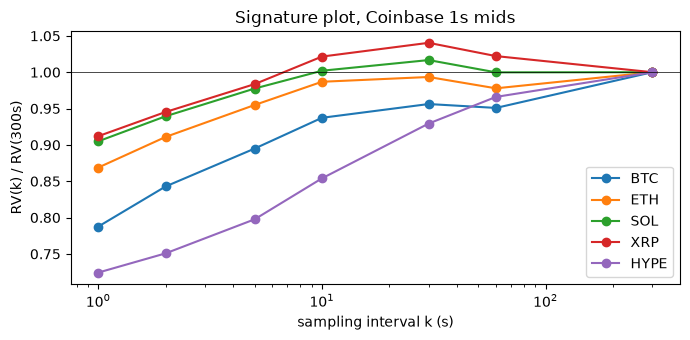

In [3]:
sig = {}
for c in COINS:
    rv = {k: np.mean([(np.diff(load_day(c, d)[0][::k]) ** 2).sum() for d in days_for(c)]) for k in [1, 2, 5, 10, 30, 60, 300]}
    sig[c] = {k: v / rv[300] for k, v in rv.items()}
sig = pd.DataFrame(sig); ax = sig.plot(logx=True, marker='o', figsize=(7, 3.5))
ax.axhline(1, c='k', lw=.5); ax.set_xlabel('sampling interval k (s)'); ax.set_ylabel('RV(k) / RV(300s)'); ax.set_title('Signature plot, Coinbase 1s mids')
plt.tight_layout(); sig.T.round(2)

## 3. Dataset, target and scoring

- **Sample points:** every 60s from 04:00 UTC each day. The 4-hour warm-up is needed because the longest feature window tested is 4 hours.
- **Features:** realized variance rates (per second) from 1-second returns over the last 1m, 5m, 15m, 30m, 1h and 4h. Also EWMAs of 1-second squared returns, and the same windows built from subsampled 10s/60s returns.
- **Target:** the squared future return \(r_{t\to t+h}^2\) for \(h\) = 60, 300 and 900s. This is exactly the quantity the pricer needs.
- **Score:** Gaussian negative log-likelihood of \(r_{t\to t+h}\) given the forecast variance, \(\tfrac12(\log f + r^2/f)\). This is the QLIKE loss and is robust to the noisy squared-return proxy.
  - Results are reported as the **improvement vs a scaled trailing-15-minute RV**, ×100 nats per observation; higher is better.
  - Rule of thumb: the penalty for a log-error \(\varepsilon\) in the variance is about \(\varepsilon^2/4\), so +2 corresponds to cutting the mean squared log-error of the forecast by about 0.08.
- **Validation:** leave-one-day-out across all days, with coins pooled. Every model, including the baselines, has its scale fitted out of sample.

In [4]:
m1 = pd.read_pickle('data/m1.pkl'); m1.index = pd.to_datetime(m1.index, unit='s', utc=True); m1 = m1.asfreq('1min').ffill()
test_days = sorted({d for c in COINS for d in days_for(c)})
season = seasonal_profile(m1, exclude_days=test_days)
df = pd.concat([build(c, d, season) for c in COINS for d in days_for(c)], ignore_index=True)
df['wkend'] = pd.to_datetime(df.day).dt.dayofweek.isin([5, 6]).astype(float).values
print(df.shape); df.groupby('coin').size()

(113760, 42)


coin
BTC     26070
ETH     26070
HYPE     9480
SOL     26070
XRP     26070
dtype: int64

In [5]:
def har(ws, k=1, season=False, extra=()):
    # log-HAR features; forecast = base * exp(theta @ [1, X])
    def f(d, h):
        cols = [lg(d[f'rv{k}_{W}'].values) for W in ws]
        if season: cols.append(lg(d[f'sf_{h}'].values / d['sp_900'].values))
        cols += [d[e].values if e == 'wkend' else lg(d[e].values) for e in extra]
        return np.column_stack(cols), np.full(len(d), float(h))
    return f
scaled = lambda col: (lambda d, h: (None, d[col].values * h))

res = {}
def run(name, fn, scale_only=False):
    res[name] = {h: nll(loo_days(df, h, fn, scale_only), df[f'r2_{h}'].values) for h in HORIZONS}
def table(names):
    R = pd.DataFrame(res).T; base = R.loc['trailing RV 15m']
    return ((base - R) * 100).loc[names].rename(columns=lambda h: f'{h // 60}m ahead')

## 4. Baselines: single windows and EWMA (scale fitted, no other parameters)

In [6]:
for W in [300, 900, 3600]: run(f'trailing RV {W // 60}m', scaled(f'rv1_{W}'), True)
for hl in [300, 900, 1800, 3600, 7200]: run(f'EWMA half-life {hl // 60}m', scaled(f'ewma_{hl}'), True)
table([f'trailing RV {m}m' for m in (5, 15, 60)] + [f'EWMA half-life {m}m' for m in (5, 15, 30, 60, 120)])

,1m ahead,5m ahead,15m ahead
trailing RV 5m,-1.498,-2.419,-3.435
trailing RV 15m,0.000,0.000,0.000
trailing RV 60m,-0.821,0.535,0.830
EWMA half-life 5m,0.850,0.811,0.482
EWMA half-life 15m,0.690,1.477,1.597
EWMA half-life 30m,-0.045,1.093,1.383
EWMA half-life 60m,-1.372,-0.025,0.374
EWMA half-life 120m,-3.310,-1.859,-1.375


- The best single estimator is an EWMA with a 15-minute half-life.
- Short windows win at short horizons and longer ones at long horizons.
- No single window is right for every horizon, which is what a HAR blend fixes.

## 5. HAR blends: which windows, and which return sampling

In [7]:
grid = {'HAR 5m,1h,4h': [300, 3600, 14400], 'HAR 1m,15m,4h': [60, 900, 14400], 'HAR 1m,5m,1h': [60, 300, 3600],
        'HAR 1m,15m,1h': [60, 900, 3600], 'HAR 1m,5m,1h,4h': [60, 300, 3600, 14400], 'HAR 1m,5m,15m,1h,4h': [60, 300, 900, 3600, 14400]}
for n, ws in grid.items(): run(n, har(ws))
for k in (10, 60): run(f'HAR 1m,15m,1h from {k}s returns', har([60, 900, 3600], k))
table(list(grid) + ['HAR 1m,15m,1h from 10s returns', 'HAR 1m,15m,1h from 60s returns'])

,1m ahead,5m ahead,15m ahead
"HAR 5m,1h,4h",1.572,1.810,1.725
"HAR 1m,15m,4h",1.838,1.758,1.690
"HAR 1m,5m,1h",1.886,1.929,1.731
"HAR 1m,15m,1h",1.887,1.917,1.828
"HAR 1m,5m,1h,4h",1.911,1.967,1.768
"HAR 1m,5m,15m,1h,4h",2.012,2.008,1.879
"HAR 1m,15m,1h from 10s returns",1.959,1.940,1.954
"HAR 1m,15m,1h from 60s returns",1.260,1.156,1.052


- **A 1-minute term matters,** especially for the 1-minute horizon: compare `5m,1h,4h` with `1m,15m,1h`.
- **`1m,15m,1h` keeps about 95% of the gain of the five-term model with three terms.** It also needs no 4-hour warm-up, so it's ready one hour after a restart.
- **Return sampling: 1s and 10s are about equal, and 60s is clearly worse.** Subsampled 10s returns are marginally better (+0.07 to +0.13), and both are trivial to compute live from the 1-second book. Use 10s-subsampled if you want the extra bit. The bias seen in §2 is absorbed by the intercept.

## 6. Do extra features help? (time-of-day seasonality, weekend, spread)

In [8]:
base3 = [60, 900, 3600]
run('HAR 1m,15m,1h + seasonality', har(base3, season=True))
run('HAR 1m,15m,1h + weekend', har(base3, extra=('wkend',)))
run('HAR 1m,15m,1h + spread', har(base3, extra=('spr',)))
run('EWMA 15m x seasonality (imposed)', lambda d, h: (None, d['ewma_900'].values / d['sp_900'].values * d[f'sf_{h}'].values * h), True)
table(['HAR 1m,15m,1h', 'HAR 1m,15m,1h + seasonality', 'HAR 1m,15m,1h + weekend', 'HAR 1m,15m,1h + spread', 'EWMA half-life 15m', 'EWMA 15m x seasonality (imposed)'])

,1m ahead,5m ahead,15m ahead
"HAR 1m,15m,1h",1.887,1.917,1.828
"HAR 1m,15m,1h + seasonality",1.886,1.907,1.793
"HAR 1m,15m,1h + weekend",1.835,1.848,1.725
"HAR 1m,15m,1h + spread",1.879,1.900,1.798
EWMA half-life 15m,0.690,1.477,1.597
EWMA 15m x seasonality (imposed),0.625,1.372,1.454


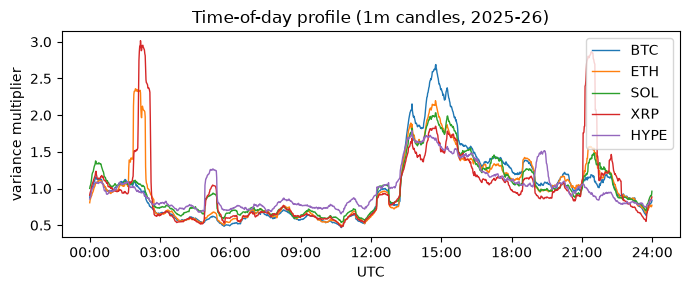

In [9]:
ax = season.plot(figsize=(7, 3), lw=1); ax.set_xticks(range(0, 1441, 180)); ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 3)])
ax.set_xlabel('UTC'); ax.set_ylabel('variance multiplier'); ax.set_title('Time-of-day profile (1m candles, 2025-26)'); plt.tight_layout()

- The time-of-day pattern is real: about 0.5× overnight to 2–3× around 13:30–15:00 UTC (the US open and data releases).
- **But once the 1-minute and 15-minute terms are in, the recent RV already tracks the current regime.** Seasonality, weekend and spread each move the score by about 0.1 or less.
- **Leave them out of the base model.** The real value is in *scheduled events* (CPI, FOMC, 8:30 ET releases) that land inside a window. Handle those with an explicit event bump, not an average profile.

## 7. Final model: `HAR 1m,15m,1h`

In [10]:
final = har(base3)
rows, coefs, preds = [], {}, {}
tr = (df.day < '20260101').values
for h in HORIZONS:
    y = df[f'r2_{h}'].values; X, b = final(df, h)
    preds[h] = p = loo_days(df, h, final); pt = loo_days(df, h, scaled('rv1_900'), True)
    fit = fit_loglinear(X[tr], y[tr] / b[tr]); ps = b[~tr] * predict_loglinear(fit, X[~tr])
    pts = df.rv1_900.values[~tr] * h * (y[tr] / (df.rv1_900.values[tr] * h)).mean()
    daygain = pd.Series((lg(pt) + y / pt - lg(p) - y / p) / 2).groupby(df.day.values).mean()
    th, mu = fit_loglinear(X, y / b); coefs[h] = dict(zip(['b_1m', 'b_15m', 'b_1h'], th[1:])) | {'sum b': th[1:].sum()}
    rows.append({'horizon': f'{h // 60}m', 'LOO gain': (nll(pt, y) - nll(p, y)) * 100,
                 'train 2025 -> test 2026 gain': (nll(pts, y[~tr]) - nll(ps, y[~tr])) * 100,
                 'share of days won': (daygain > 0).mean(), 'excess kurtosis of r/sigma': kurtosis(np.r_[np.sqrt(y / p), -np.sqrt(y / p)])})
pd.DataFrame(rows).set_index('horizon')

,LOO gain,train 2025 -> test 2026 gain,share of days won,excess kurtosis of r/sigma
horizon,,,,
1m,1.887,1.697,1.000,5.171
5m,1.917,1.608,0.909,3.982
15m,1.828,1.722,0.864,3.126


In [11]:
pd.DataFrame(coefs).T.rename(index=lambda h: f'{h // 60}m')

,b_1m,b_15m,b_1h,sum b
1m,0.234,0.359,0.288,0.880
5m,0.165,0.270,0.459,0.893
15m,0.093,0.302,0.489,0.884


In [12]:
calib = pd.DataFrame({f'{h // 60}m': pd.Series(df[f'r2_{h}'].values / preds[h]).groupby(df.coin.values).mean() for h in HORIZONS})
calib.loc[COINS]   # mean(r^2 / forecast); 1.0 = unbiased

,1m,5m,15m
BTC,0.980,0.996,0.987
ETH,1.012,1.003,1.023
SOL,0.974,0.979,0.984
XRP,0.982,0.980,0.976
HYPE,1.159,1.152,1.130


**Reading the results**

- **Robust.** The gain holds when trained on 2025 and tested on 2026, and the model wins on 86–100% of individual days.
- **Coefficient pattern.** At a 1-minute horizon the 1-minute term carries the most weight; at 15 minutes the 1-hour term dominates. The coefficients sum to about 0.88, which means vol shocks mean-revert. For any \(h\) in between, interpolate the coefficients linearly in \(\log h\).
- **Calibration.** BTC, ETH, SOL and XRP are within ±3% on average. **HYPE is under-forecast by about 15%,** consistent with its stickier 1-second mid. Apply a per-coin scale \(c_{HYPE}\approx 1.15\), re-estimated from a rolling mean of \(r^2/f\).
- **Fat tails.** Standardized returns have excess kurtosis of about 3–5, higher at short horizons. That's roughly a Student-t with \(\nu \approx 5\)–6. Use this for the pricer's fat-tail mixture.

## 8. Plugging it into the pricer

In [13]:
FIT = {h: fit_loglinear(*(lambda X, b: (X, df[f'r2_{h}'].values / b))(*final(df, h))) for h in HORIZONS}
COIN_SCALE = calib['15m'].round(2).to_dict()

def forecast_var(h, rv1m, rv15m, rv1h, coin):
    # Variance of the log return over the next h seconds. rv* are per-second RV rates from 1s Coinbase mids.
    hs = np.array(HORIZONS, float); lh = np.clip(np.log(h), np.log(hs[0]), np.log(hs[-1]))
    x = np.log([[rv1m, rv15m, rv1h]])
    lv = [np.log(predict_loglinear(FIT[k], x)[0]) for k in HORIZONS]   # per-second variance rate at each fitted horizon
    return h * np.exp(np.interp(lh, np.log(hs), lv)) * COIN_SCALE.get(coin, 1.0)

r = df.iloc[50000]
print(r.coin, {h: f'{np.sqrt(forecast_var(h, r.rv1_60, r.rv1_900, r.rv1_3600, r.coin)) * 1e4:.1f} bp' for h in (30, 60, 300, 900)})

ETH {30: '3.7 bp', 60: '5.3 bp', 300: '11.5 bp', 900: '20.2 bp'}


**Wiring into `CovarianceForecaster`**

1. Live: keep running sums of 1-second squared log returns over the last 60s, 900s and 3600s for each coin. These are \(O(1)\) updates per second.
2. `forecast_cov(t0, t1)`: for the diagonal, use `forecast_var` with \(h = t1 - t0\), applying the §4.2/§4.3 weighting for the last-minute averaging. For off-diagonals, multiply the volatilities by a slow correlation matrix (half-life 4–24h, estimated from 30–60s returns). That's a separate, low-impact choice per the earlier test.
3. Refit the 4 × 3 coefficients and `COIN_SCALE` weekly on accumulated live 1-second data, and keep the same leave-one-day-out check before promoting.

**Caveats**
- There are only 22 days (8 for HYPE), all on the first of the month.
- Model *ranking* is stable, but coefficients will tighten with live data.
- Add the scheduled-event bump separately.